## EDA

 01 - Data Understanding

 Project: LLM Inference Latency Prediction

 Objective:
The objective of this project is to predict the total
inference latency of Large Language Model requests
using supervised machine learning regression.

Target Variable:
Total_Latency_ms

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = 'llm_inference_logs.csv'

In [3]:
df = pd.read_csv(
    '../data/LLM Inference Logs & Performance Metrics/llm_inference_logs.csv'
)

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [5]:
df.head()

,timestamp,model_name,task_type,provider,prompt_tokens,completion_tokens,cache_hit_tokens,ttft_ms,tpot_ms,total_latency_ms,estimated_cost_usd,status_code
0,2026-06-01 00:02:21,claude-3-5-sonnet,Summarization,Anthropic_API,16155,795,0,83,36.30,28854,0.060879,200
1,2026-06-01 00:02:29,claude-3-5-sonnet,Summarization,Anthropic_API,8489,616,143,98,27.91,17207,0.035168,200
2,2026-06-01 00:20:19,llama-3-70b-instruct,Summarization,Together_AI,50,59,0,53,18.56,1111,0.000098,200
3,2026-06-01 00:47:39,mistral-7b-instruct,Summarization,Self_Hosted_vLLM,3633,663,0,26,11.81,7871,0.000865,200
4,2026-06-01 00:50:02,llama-3-70b-instruct,Code_Generation,Together_AI,383,1723,0,61,18.39,31818,0.001880,200


In [6]:
df.tail()

,timestamp,model_name,task_type,provider,prompt_tokens,completion_tokens,cache_hit_tokens,ttft_ms,tpot_ms,total_latency_ms,estimated_cost_usd,status_code
29995,2026-06-14 23:35:27,claude-3-5-sonnet,Summarization,Anthropic_API,6703,363,0,81,30.98,11304,0.025451,200
29996,2026-06-14 23:39:03,llama-3-70b-instruct,Code_Generation,Together_AI,3189,1074,0,80,18.96,20400,0.003844,200
29997,2026-06-14 23:41:06,claude-3-5-sonnet,Extraction_JSON,Anthropic_API,1885,240,0,72,30.63,7348,0.009342,200
29998,2026-06-14 23:42:29,llama-3-70b-instruct,Customer_Support_Chat,Together_AI,402,50,0,42,22.45,1069,0.000403,200
29999,2026-06-14 23:48:54,llama-3-70b-instruct,Customer_Support_Chat,Together_AI,405,154,0,66,13.33,2144,0.000494,200


In [7]:
print("Number of observations:", df.shape[0])
print("Number of features:", df.shape[1])

Number of observations: 30000
Number of features: 12


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   timestamp           30000 non-null  str    
 1   model_name          30000 non-null  str    
 2   task_type           30000 non-null  str    
 3   provider            30000 non-null  str    
 4   prompt_tokens       30000 non-null  int64  
 5   completion_tokens   30000 non-null  int64  
 6   cache_hit_tokens    30000 non-null  int64  
 7   ttft_ms             30000 non-null  int64  
 8   tpot_ms             30000 non-null  float64
 9   total_latency_ms    30000 non-null  int64  
 10  estimated_cost_usd  28519 non-null  float64
 11  status_code         30000 non-null  int64  
dtypes: float64(2), int64(6), str(4)
memory usage: 2.7 MB


In [10]:
display(
    pd.DataFrame({
        "Data Type": df.dtypes,
        "Unique Values": df.nunique(),
        "Missing Values": df.isnull().sum()
    })
)

,Data Type,Unique Values,Missing Values
timestamp,str,29356,0
model_name,str,4,0
task_type,str,4,0
provider,str,4,0
prompt_tokens,int64,7952,0
completion_tokens,int64,1701,0
cache_hit_tokens,int64,810,0
ttft_ms,int64,201,0
tpot_ms,float64,3068,0
total_latency_ms,int64,17539,0


In [11]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
prompt_tokens,30000.0,3543.075533,10774.100199,50.0,465.000000,1436.000000,2803.000000,129863.000000
completion_tokens,30000.0,478.917800,358.573486,0.0,208.000000,370.000000,697.250000,2429.000000
cache_hit_tokens,30000.0,44.989000,418.140192,0.0,0.000000,0.000000,0.000000,21635.000000
ttft_ms,30000.0,76.301300,32.895529,10.0,52.000000,72.000000,97.000000,225.000000
tpot_ms,30000.0,22.657067,6.973541,0.0,17.300000,22.955000,28.170000,42.580000
total_latency_ms,30000.0,11241.409800,9610.067512,10.0,4106.750000,8113.500000,15997.000000,89708.000000
estimated_cost_usd,28519.0,0.010075,0.021662,0.0,0.000948,0.004312,0.012878,0.375265
status_code,30000.0,205.696800,39.658325,200.0,200.000000,200.000000,200.000000,500.000000


In [12]:
display(
    df.describe(include="str").T
)

,count,unique,top,freq
timestamp,30000,29356,2026-06-02 16:16:53,3
model_name,30000,4,gpt-4o,10464
task_type,30000,4,Customer_Support_Chat,8877
provider,30000,4,OpenAI_API,10464


02- Missing-value analysis

In [13]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

display(
    missing_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
estimated_cost_usd,1481,4.936667
timestamp,0,0.000000
task_type,0,0.000000
model_name,0,0.000000
provider,0,0.000000
prompt_tokens,0,0.000000
cache_hit_tokens,0,0.000000
completion_tokens,0,0.000000
ttft_ms,0,0.000000
tpot_ms,0,0.000000


In [14]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

for col in numerical_columns:

    print(f"\nFeature: {col}")

    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())


Feature: prompt_tokens
Minimum: 50
Maximum: 129863
Mean: 3543.075533333333
Median: 1436.0

Feature: completion_tokens
Minimum: 0
Maximum: 2429
Mean: 478.9178
Median: 370.0

Feature: cache_hit_tokens
Minimum: 0
Maximum: 21635
Mean: 44.989
Median: 0.0

Feature: ttft_ms
Minimum: 10
Maximum: 225
Mean: 76.3013
Median: 72.0

Feature: tpot_ms
Minimum: 0.0
Maximum: 42.58
Mean: 22.657067333333334
Median: 22.955

Feature: total_latency_ms
Minimum: 10
Maximum: 89708
Mean: 11241.4098
Median: 8113.5

Feature: estimated_cost_usd
Minimum: 0.0
Maximum: 0.375265
Mean: 0.01007526456046846
Median: 0.004312

Feature: status_code
Minimum: 200
Maximum: 500
Mean: 205.6968
Median: 200.0


In [31]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:

    print(f"\nFeature: {col}")

    print(df[col].value_counts(dropna=False))


Feature: timestamp
timestamp
2026-06-02 16:16:53    3
2026-06-03 11:22:18    3
2026-06-04 09:16:38    3
2026-06-04 12:23:10    3
2026-06-05 17:23:13    3
                      ..
2026-06-14 23:35:27    1
2026-06-14 23:39:03    1
2026-06-14 23:41:06    1
2026-06-14 23:42:29    1
2026-06-14 23:48:54    1
Name: count, Length: 29356, dtype: int64

Feature: model_name
model_name
gpt-4o                  10464
llama-3-70b-instruct     7573
claude-3-5-sonnet        7489
mistral-7b-instruct      4474
Name: count, dtype: int64

Feature: task_type
task_type
Customer_Support_Chat    8877
Code_Generation          7965
Summarization            7548
Extraction_JSON          5610
Name: count, dtype: int64

Feature: provider
provider
OpenAI_API          10464
Anthropic_API        7489
Together_AI          7408
Self_Hosted_vLLM     4639
Name: count, dtype: int64


C:\Users\ASUS\AppData\Local\Temp\ipykernel_14852\1323305574.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [16]:
# Select numerical columns
numerical_columns = df.select_dtypes(
    include=["number"]
).columns

# Calculate descriptive statistics
range_summary = df[numerical_columns].agg(
    ["min", "max", "mean", "median", "std"]
).T

# Calculate range
range_summary["range"] = (
    range_summary["max"] - range_summary["min"]
)

range_summary

,min,max,mean,median,std,range
prompt_tokens,50.0,129863.000000,3543.075533,1436.000000,10774.100199,129813.000000
completion_tokens,0.0,2429.000000,478.917800,370.000000,358.573486,2429.000000
cache_hit_tokens,0.0,21635.000000,44.989000,0.000000,418.140192,21635.000000
ttft_ms,10.0,225.000000,76.301300,72.000000,32.895529,215.000000
tpot_ms,0.0,42.580000,22.657067,22.955000,6.973541,42.580000
total_latency_ms,10.0,89708.000000,11241.409800,8113.500000,9610.067512,89698.000000
estimated_cost_usd,0.0,0.375265,0.010075,0.004312,0.021662,0.375265
status_code,200.0,500.000000,205.696800,200.000000,39.658325,300.000000


In [17]:
df["estimated_cost_usd"] = df["estimated_cost_usd"].fillna(0)

In [18]:
df.isnull().sum()

timestamp             0
model_name            0
task_type             0
provider              0
prompt_tokens         0
completion_tokens     0
cache_hit_tokens      0
ttft_ms               0
tpot_ms               0
total_latency_ms      0
estimated_cost_usd    0
status_code           0
dtype: int64

In [19]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

timestamp
<StringArray>
['2026-06-01 00:02:21', '2026-06-01 00:02:29', '2026-06-01 00:20:19',
 '2026-06-01 00:47:39', '2026-06-01 00:50:02']
Length: 5, dtype: str
29356

model_name
<StringArray>
['claude-3-5-sonnet', 'llama-3-70b-instruct', 'mistral-7b-instruct', 'gpt-4o']
Length: 4, dtype: str
4

task_type
<StringArray>
['Summarization', 'Code_Generation', 'Customer_Support_Chat',
 'Extraction_JSON']
Length: 4, dtype: str
4

provider
<StringArray>
['Anthropic_API', 'Together_AI', 'Self_Hosted_vLLM', 'OpenAI_API']
Length: 4, dtype: str
4

prompt_tokens
[16155  8489    50  3633   383]
7952

completion_tokens
[ 795  616   59  663 1723]
1701

cache_hit_tokens
[  0 143 140  10 241]
810

ttft_ms
[83 98 53 26 61]
201

tpot_ms
[36.3  27.91 18.56 11.81 18.39]
3068

total_latency_ms
[28854 17207  1111  7871 31818]
17539

estimated_cost_usd
[6.0879e-02 3.5168e-02 9.8000e-05 8.6500e-04 1.8800e-03]
14754

status_code
[200 500 400 429]
4



In [20]:
categorical = [
  'provider', 'task_type ',
  'model_name','timestamp '
]


numerical = [ 
'prompt_tokens',        
'completion_tokens',   
'cache_hit_tokens',     
'ttft_ms',              
'tpot_ms',            
'total_latency_ms'     
'estimated_cost_usd'  
'status_code'   
]

<Axes: xlabel='total_latency_ms', ylabel='Count'>

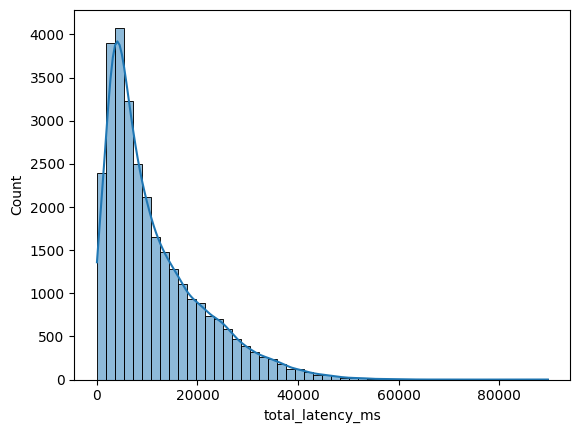

In [21]:
sns.histplot(
    data=df,
    x="total_latency_ms",
    bins=50,
    kde=True
)

In [25]:
total_latency_ms = np.log1p(df.total_latency_ms)

<Axes: xlabel='total_latency_ms', ylabel='Count'>

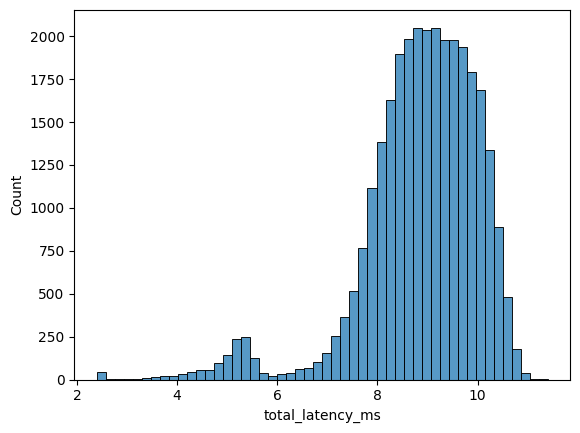

In [27]:
sns.histplot(total_latency_ms, bins=50)

In [28]:
target = "total_latency_ms"
df[target].describe()

count    30000.000000
mean     11241.409800
std       9610.067512
min         10.000000
25%       4106.750000
50%       8113.500000
75%      15997.000000
max      89708.000000
Name: total_latency_ms, dtype: float64

In [30]:
corr_matrix = df.corr(method='pearson', numeric_only=True)

feature_importance = (
    corr_matrix['total_latency_ms']
    .drop('total_latency_ms', errors='ignore')
    .abs()
    .sort_values(ascending=False)
)

print(feature_importance)


##the most important feature to predict Total_Latency_ms is Completion_tokens and the less important feature is cache_Hit_Tokens.

completion_tokens     0.909483
tpot_ms               0.437939
estimated_cost_usd    0.316623
ttft_ms               0.280964
status_code           0.165026
prompt_tokens         0.040357
cache_hit_tokens      0.027330
Name: total_latency_ms, dtype: float64
